# Overview on Telemetry Data and Test-Case Results
4 Telemetry data selected:
* **`temperature_c`**: Monitored at bearings, lubrication loops, or process fluids to track thermal friction and cooling efficiency.
* **`vibration_hz`**: Tracks mechanical oscillations to detect shaft misalignment, rotor imbalance, or bearing degradation.
* **`pressure_psi`**: Measures internal discharge, suction, or hydraulic line pressures.
* **`power_kw`**: Tracks real-time electrical or shaft power consumption, serving as an indicator of load and motor efficiency.

These telemetry can be part of telemetry data for example Multistage Centrifugal Water Pump (a critical asset used in industrial water distribution, boiler feeding, and oil production.

In this notebook we explain and illustrate the assumption used for these telemetry in normal and anomaly scenario

In [1]:
from pathlib import Path
import sys
SRC_DIR = str(Path.cwd().parent /'src')
if SRC_DIR not in sys.path:
    sys.path.append(SRC_DIR)

In [2]:
import importlib
from config import settings
import utils as ut #use importlib.reload(ut) if reload needed in specific cell during development
from tools.severity_bands_tools import get_severity_bands, get_telemetry_normal_range
from tools.anomaly_detector_tool import detect_anomaly
from tools.ltm_db_tools import get_ltm_df
from tools.telemetry_db_tools import get_telemetry_df

import seaborn as sns
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib # for version check
import matplotlib.pyplot as plt

from IPython.display import clear_output, display, Image

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
# Enable high-resolution Retina plots
%config InlineBackend.figure_format = 'retina'

In [3]:
print("*" * 75)
print(f'PYTHON VERSION:      {sys.version}')
print(f'PYTHON VPATH:        {sys.executable}')
print(f"Pandas version:      {pd.__version__}")
print(f"NumPy version:       {np.__version__}")
print(f"Matplotlib version:  {matplotlib.__version__}")
print(f"Seaborn version:     {sns.__version__}")
print("*" * 75)

***************************************************************************
PYTHON VERSION:      3.13.14 (main, Jul 23 2026, 14:44:45) [Clang 22.1.3 ]
PYTHON VPATH:        /home/max/x/zc06-agentic-ai-sys/.venv/bin/python
Pandas version:      3.0.5
NumPy version:       2.5.3
Matplotlib version:  3.11.2
Seaborn version:     0.13.2
***************************************************************************


In [4]:
random.seed(settings.RANDOM_SEED)
np.random.seed(settings.RANDOM_SEED)
DPI=300 # use dpi when saving figures/plots

# Normal and Anomaly Region

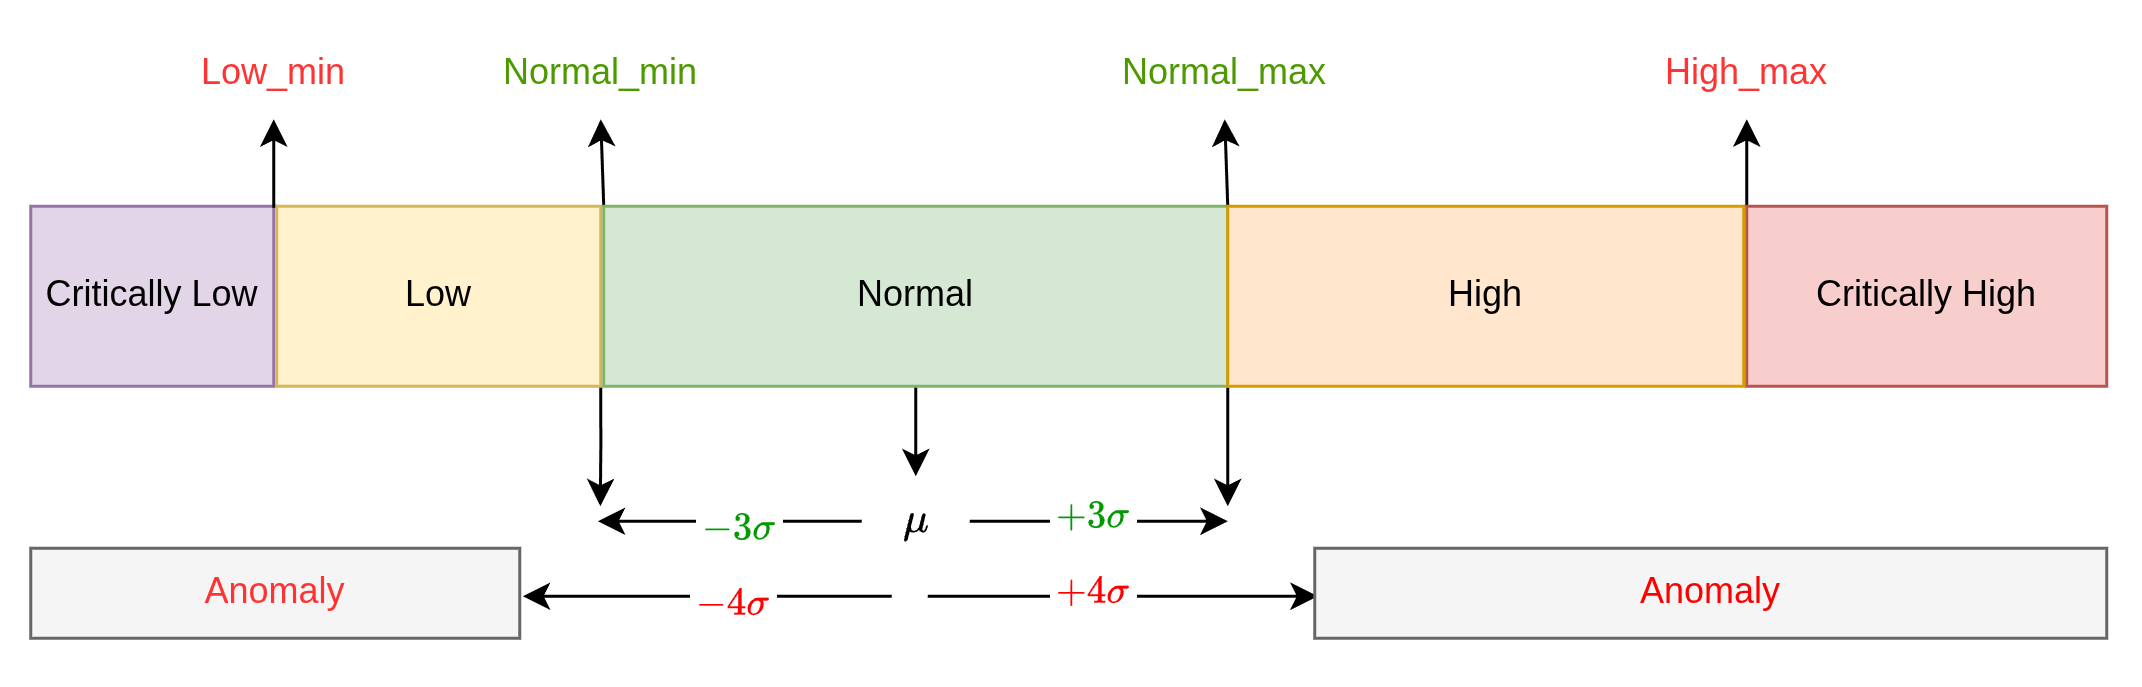

In [5]:
display(Image(filename=settings.IMG_DIR/'severity_bands.drawio.png', width=800))

# Workflow Graph (LangChain/LangGraph)

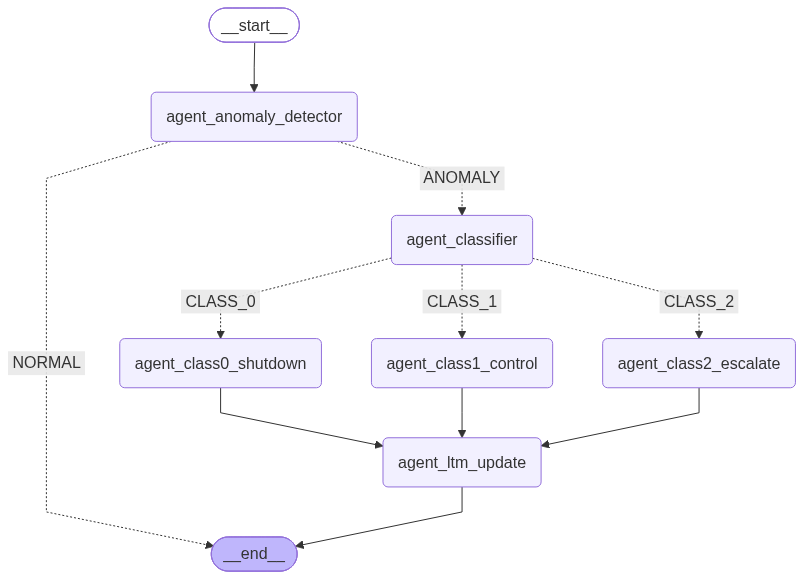

In [6]:
display(Image(filename=settings.IMG_DIR/'workflow_graph.png', width=800))

# Asset Parameters and Start-End for Test Cases
- 3 asset defined with slightly different parameters (low_min, normal_min, normal_max, high_max)
- For test cases: Generally we use start in normal region, and end in anomaly region
- start4, end4 are in normal region, as a place holder for another anomaly

In [7]:
df= pd.read_csv(settings.DATA_DIR/'test_case_and_asset_info.csv')
df

,asset_index,parameter,low_min,normal_min,normal_max,high_max,start1,end1,start2,end2,start3,end3,start4,end4
0,1,temperature_c,40,48,62,80,50,70,50,79,50,90,50,59
1,1,vibration_hz,15,20,32,44,22,29,22,29,22,29,22,29
2,1,pressure_psi,80,111,130,160,114,125,114,135,114,125,114,125
3,1,power_kw,30,42,52,60,44,48,44,48,44,48,44,48
4,0,p,0,0,0,0,0,0,0,0,0,0,0,0
5,2,temperature_c,41,49,63,81,51,60,51,60,51,60,51,60
6,2,vibration_hz,16,21,33,45,23,35,23,40,23,50,23,30
7,2,pressure_psi,81,112,131,161,116,129,116,140,116,129,116,129
8,2,power_kw,31,43,53,61,45,49,45,49,45,49,45,49
9,0,p,0,0,0,0,0,0,0,0,0,0,0,0


# Test Cases
- The graph shows 10 samples and possible way that telemetry are changing from start to end
- We only feed start and end samples to the our agentic system  to see the system behavior
- we can feed more sample, but because we do not have real closed loop system, our agentic   is practically decide on last sample include last 3 previous results as context

# Asset-1, Test-1, Samples-2
-  High Temperature, should be CLASS_2 and detected as CLASS_2

In [ ]:
asset_id, case_id, samples, title= 1,1,2,'High Temperature'
df_cfg=ut.get_asset_test_case(asset_index=asset_id, test_case_index=case_id)
df = ut.generate_test_case_data(df_cfg, num_samples=10,trend='sigmoid', sigmoid_steepness=6.0)
ut.plot_test_case_telemetry(df,df_cfg, f'Asset-{asset_id}, Test-Case-{case_id}: {title}',test_point=True)
plt.savefig(settings.IMG_DIR/'a1t1', dpi=DPI)

In [ ]:
display(Image(filename=settings.IMG_DIR/'a1t1s2.png', width=1200))

# Asset-1, Test-2, Samples-2
- Two telemetries in High Severity Bands should be CLASS_2, and detected as CLASS_2

In [ ]:
asset_id, case_id, samples, title= 1,2,2,'High Temperature, High Pressure'
df_cfg=ut.get_asset_test_case(asset_index=asset_id, test_case_index=case_id)
df = ut.generate_test_case_data(df_cfg, num_samples=10,trend='sigmoid', sigmoid_steepness=6.0)
ut.plot_test_case_telemetry(df,df_cfg, f'Asset-{asset_id}, Test-Case-{case_id}: {title}',test_point=True)
plt.savefig(settings.IMG_DIR/'a1t2', dpi=DPI)

In [ ]:
display(Image(filename=settings.IMG_DIR/'a1t2s2.png', width=1200))

# Asset-1, Test-3, Samples-2
- Any of 3 telemetry: Temperature, Pressure, or  Vibration in Critically High bands should be CLASS_0 (immediate Shutdown), and detected as CLASS_0

In [ ]:
asset_id, case_id, samples, title= 1,3,2,'Critically High Temperature'
df_cfg=ut.get_asset_test_case(asset_index=asset_id, test_case_index=case_id)
df = ut.generate_test_case_data(df_cfg, num_samples=10,trend='sigmoid', sigmoid_steepness=6.0)
ut.plot_test_case_telemetry(df,df_cfg, f'Asset-{asset_id}, Test-Case-{case_id}: {title}',test_point=True)
plt.savefig(settings.IMG_DIR/'a1t3', dpi=DPI)

In [ ]:
display(Image(filename=settings.IMG_DIR/'a1t3s2.png', width=1200))

# Asset-2, Test-1, Samples-2
- We do not control High Vibration, and it should be CLASS_2 and detected as CLASS_2

In [ ]:
asset_id, case_id, samples, title= 2,1,2,'High Viberation'
df_cfg=ut.get_asset_test_case(asset_index=asset_id, test_case_index=case_id)
df = ut.generate_test_case_data(df_cfg, num_samples=10,trend='sigmoid', sigmoid_steepness=6.0)
ut.plot_test_case_telemetry(df,df_cfg, f'Asset-{asset_id}, Test-Case-{case_id}: {title}',test_point=True)
plt.savefig(settings.IMG_DIR/'a2t1', dpi=DPI)

In [ ]:
display(Image(filename=settings.IMG_DIR/'a2t1s2.png', width=1200))

# Asset-2, Test-2, Samples-2
- 2 High Anomaly, should be CLASS_2 and detected as CLASS_2

In [ ]:
asset_id, case_id, samples, title= 2,2,2,'High Viberation, and High Pressure'
df_cfg=ut.get_asset_test_case(asset_index=asset_id, test_case_index=case_id)
df = ut.generate_test_case_data(df_cfg, num_samples=10,trend='sigmoid', sigmoid_steepness=6.0)
ut.plot_test_case_telemetry(df,df_cfg, f'Asset-{asset_id}, Test-Case-{case_id}: {title}',test_point=True)
plt.savefig(settings.IMG_DIR/'a2t2', dpi=DPI)

In [ ]:
display(Image(filename=settings.IMG_DIR/'a2t2s2.png', width=1200))

# Asset-2, Test-3, Samples-2
- Any of 3 telemetry: Temperature, Pressure, or  Vibration in Critically High bands should be CLASS_0 (immediate Shutdown), and detected as CLASS_0

In [ ]:
asset_id, case_id, samples, title= 2,3,2,'Critically High Viberation'
df_cfg=ut.get_asset_test_case(asset_index=asset_id, test_case_index=case_id)
df = ut.generate_test_case_data(df_cfg, num_samples=10,trend='sigmoid', sigmoid_steepness=6.0)
ut.plot_test_case_telemetry(df,df_cfg, f'Asset-{asset_id}, Test-Case-{case_id}: {title}',test_point=True)
plt.savefig(settings.IMG_DIR/'a2t3', dpi=DPI)

In [ ]:
display(Image(filename=settings.IMG_DIR/'a2t3s2.png', width=1200))

# Asset-3, Test-1, Samples-2
- Any of 3 telemetry: Temperature, Pressure, or  Vibration in Critically High bands should be CLASS_0 (immediate Shutdown), and detected as CLASS_0

In [ ]:
asset_id, case_id, samples, title= 3,1,2,'Critically High Pressure'
df_cfg=ut.get_asset_test_case(asset_index=asset_id, test_case_index=case_id)
df = ut.generate_test_case_data(df_cfg, num_samples=10,trend='sigmoid', sigmoid_steepness=6.0)
ut.plot_test_case_telemetry(df,df_cfg, f'Asset-{asset_id}, Test-Case-{case_id}: {title}',test_point=True)
plt.savefig(settings.IMG_DIR/'a3t1', dpi=DPI)

In [ ]:
display(Image(filename=settings.IMG_DIR/'a3t1s2.png', width=1200))

# Asset-3, Test-2, Samples-2
- We control Low Pressure with VFD as CLASS_1, and it detected as CLASS_1

In [ ]:
asset_id, case_id, samples, title= 3,2,2,'Low Pressure'
df_cfg=ut.get_asset_test_case(asset_index=asset_id, test_case_index=case_id)
df = ut.generate_test_case_data(df_cfg, num_samples=10,trend='sigmoid', sigmoid_steepness=6.0)
ut.plot_test_case_telemetry(df,df_cfg, f'Asset-{asset_id}, Test-Case-{case_id}: {title}',test_point=True)
plt.savefig(settings.IMG_DIR/'a3t2', dpi=DPI)

In [ ]:
display(Image(filename=settings.IMG_DIR/'a3t2s2.png', width=1200))

# Asset-3, Test-3, Samples-2 and effect of using or not using LTM as context
- We can control High Power with VFD as Class_1
- However if It keep happening and log in LTM, and agent using LTM, It's logical to escalate and consider CLASS_2

In [ ]:
asset_id, case_id, samples, title= 3,3,2,'High Power'
df_cfg=ut.get_asset_test_case(asset_index=asset_id, test_case_index=case_id)
df = ut.generate_test_case_data(df_cfg, num_samples=10,trend='sigmoid', sigmoid_steepness=6.0)
ut.plot_test_case_telemetry(df,df_cfg, f'Asset-{asset_id}, Test-Case-{case_id}: {title}',test_point=True)
plt.savefig(settings.IMG_DIR/'a3t3', dpi=DPI)

## Without LTM

In [ ]:
display(Image(filename=settings.IMG_DIR/'a3t3s2_no_ltm.png', width=1200))

## With LTM after several time repeating to fill LTM with same behavior

In [ ]:
display(Image(filename=settings.IMG_DIR/'a3t3s2.png', width=1200))

# Multiple samples
- We can send more than 2 samples to systems, and it can route to designated CLASS, however here we do not have close loop to really see the effect of agent classification
- For example if agent use VFD to reduce the pressure, we may expect to see lower pressure in next samples, but sending original simulated sample can still increase the pressure
- overall adding close loop can be part of future work, and here we just demonstrate that system can work on more than 2 samples (continuous steam of samples)

In [ ]:
asset_id, case_id, samples, title= 3,1,5,'Pressure from Normal to High, to Critically High'
df_cfg=ut.get_asset_test_case(asset_index=asset_id, test_case_index=case_id)
df = ut.generate_test_case_data(df_cfg, num_samples=5,trend='sigmoid', sigmoid_steepness=6.0)
ut.plot_test_case_telemetry(df,df_cfg, f'Asset-{asset_id}, Test-Case-{case_id}: {title}',test_point=True)
plt.savefig(settings.IMG_DIR/'a3t1_5samples', dpi=DPI)

In [ ]:
display(Image(filename=settings.IMG_DIR/'a3t1s5.png', width=1200))

# Analytics

In [ ]:
display(Image(filename=settings.IMG_DIR/'token_usage.png', width=1200))

In [ ]:
display(Image(filename=settings.IMG_DIR/'tool_usage.png', width=1200))

In [ ]:
display(Image(filename=settings.IMG_DIR/'func_usage.png', width=1200))

# Check dB

In [ ]:
df_telemetry = get_telemetry_df()
df_telemetry.sample(10)

In [ ]:
df_ltm = get_ltm_df()
df_ltm.sample(10)

In [ ]:
from tools.checkpoint_db_analytics import get_checkpoint_df
df_checkpoint = get_checkpoint_df()
print(f'Checkpoint-dB: colums= {df_checkpoint.columns.to_list()}') # ['thread_id', 'checkpoint_ns', 'checkpoint_id', 'parent_checkpoint_id', 'type', 'checkpoint', 'metadata']
print(f'Checkpoint-dB: shape={df_checkpoint.shape}')
df_checkpoint.sample(1)